# 🛡️ Phishing Website Detector

A self-contained machine-learning project that extracts features from a URL and predicts whether it is **legitimate or phishing**. The notebook generates a realistic synthetic training dataset, trains a Random Forest classifier, evaluates it, and provides an interactive URL checker.

In [1]:
import re
import math
import random
import warnings
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings('ignore')
random.seed(42)
np.random.seed(42)

print('Libraries loaded successfully.')

Libraries loaded successfully.


## 1. Feature extraction

The model uses URL-level signals such as length, suspicious characters, IP-address usage, HTTPS, subdomains, redirects, and phishing-related keywords.

In [2]:
SUSPICIOUS_WORDS = [
    'login', 'signin', 'verify', 'verification', 'account', 'secure',
    'update', 'confirm', 'bank', 'wallet', 'password', 'credential',
    'payment', 'invoice', 'recover', 'unlock', 'security'
]

SHORTENERS = ['bit.ly', 'tinyurl.com', 't.co', 'goo.gl', 'is.gd', 'ow.ly']

def entropy(text):
    if not text:
        return 0.0
    counts = np.bincount(np.frombuffer(text.encode('utf-8'), dtype=np.uint8))
    probs = counts[counts > 0] / len(text)
    return float(-(probs * np.log2(probs)).sum())

def extract_features(url):
    original = str(url).strip()
    candidate = original if re.match(r'^https?://', original, re.I) else 'http://' + original
    parsed = urlparse(candidate)
    host = parsed.netloc.lower().split('@')[-1].split(':')[0]
    path_query = (parsed.path + '?' + parsed.query).lower()
    full = candidate.lower()

    ip_pattern = r'^(?:\d{1,3}\.){3}\d{1,3}$'
    has_ip = int(bool(re.match(ip_pattern, host)))
    subdomain_count = max(0, len(host.split('.')) - 2)
    suspicious_word_count = sum(word in full for word in SUSPICIOUS_WORDS)
    digit_count = sum(ch.isdigit() for ch in full)
    special_count = sum(ch in '@?&=%_-;' for ch in full)

    features = {
        'url_length': len(original),
        'hostname_length': len(host),
        'path_length': len(parsed.path),
        'num_dots': full.count('.'),
        'num_hyphens': full.count('-'),
        'num_digits': digit_count,
        'num_special_chars': special_count,
        'num_subdomains': subdomain_count,
        'has_ip': has_ip,
        'uses_https': int(parsed.scheme.lower() == 'https'),
        'has_at_symbol': int('@' in full),
        'has_question_mark': int('?' in full),
        'has_equals': int('=' in full),
        'has_percent_encoding': int('%' in full),
        'has_port': int(parsed.port is not None) if parsed.hostname else 0,
        'suspicious_word_count': suspicious_word_count,
        'is_shortener': int(any(s in host for s in SHORTENERS)),
        'path_entropy': entropy(path_query),
    }
    return features

## 2. Build a training dataset

To keep this notebook completely self-contained, we generate labeled examples from legitimate and phishing-like URL templates. The resulting dataset is suitable for demonstrating the ML pipeline without downloading an external CSV.

In [3]:
LEGIT_DOMAINS = [
    'google.com', 'microsoft.com', 'apple.com', 'github.com', 'wikipedia.org',
    'amazon.com', 'adobe.com', 'python.org', 'mozilla.org', 'openai.com',
    'linkedin.com', 'stackoverflow.com', 'netflix.com', 'spotify.com'
]

LEGIT_PATHS = [
    '/', '/home', '/about', '/products', '/support', '/docs', '/blog',
    '/account/settings', '/search?q=python', '/help/article', '/news'
]

PHISH_BRANDS = ['paypal', 'microsoft', 'apple', 'amazon', 'bank', 'wallet', 'office365', 'netflix']
PHISH_TLDS = ['.xyz', '.top', '.click', '.site', '.online', '.info']

def random_legitimate_url():
    domain = random.choice(LEGIT_DOMAINS)
    scheme = random.choices(['https', 'http'], weights=[0.92, 0.08])[0]
    path = random.choice(LEGIT_PATHS)
    if random.random() < 0.15:
        path += '&page=' + str(random.randint(1, 20)) if '?' in path else '?page=' + str(random.randint(1, 20))
    return f'{scheme}://www.{domain}{path}'

def random_phishing_url():
    brand = random.choice(PHISH_BRANDS)
    style = random.randint(0, 5)
    if style == 0:
        domain = brand + '-' + random.choice(['secure', 'verify', 'login', 'support']) + random.choice(PHISH_TLDS)
        return 'http://' + domain + '/login/verify/account'
    if style == 1:
        return f'http://{brand}.secure-login' + random.choice(PHISH_TLDS) + '/account/update?session=' + str(random.randint(100000,999999))
    if style == 2:
        return f'http://{random.randint(10,250)}.{random.randint(1,250)}.{random.randint(1,250)}.{random.randint(1,250)}/' + random.choice(['login','verify','payment'])
    if style == 3:
        return f'https://{brand}.com@secure-' + brand + random.choice(PHISH_TLDS) + '/signin'
    if style == 4:
        return f'http://www.{brand}.com.' + random.choice(['verify', 'secure', 'account']) + random.choice(PHISH_TLDS) + '/confirm/password'
    return f'http://{brand}-account-security' + random.choice(PHISH_TLDS) + '/update/credential?token=' + ''.join(random.choices('abcdef0123456789', k=20))

rows = []
for _ in range(3000):
    url = random_legitimate_url()
    rows.append({**extract_features(url), 'label': 0, 'url': url})
for _ in range(3000):
    url = random_phishing_url()
    rows.append({**extract_features(url), 'label': 1, 'url': url})

df = pd.DataFrame(rows).sample(frac=1, random_state=42).reset_index(drop=True)
feature_cols = [c for c in df.columns if c not in ['label', 'url']]

print(f'Dataset size: {len(df):,} URLs')
print(df['label'].value_counts().rename({0: 'Legitimate', 1: 'Phishing'}))
display(df.head())

Dataset size: 6,000 URLs
label
Legitimate    3000
Phishing      3000
Name: count, dtype: int64


,url_length,hostname_length,path_length,num_dots,num_hyphens,num_digits,num_special_chars,num_subdomains,has_ip,uses_https,has_at_symbol,has_question_mark,has_equals,has_percent_encoding,has_port,suspicious_word_count,is_shortener,path_entropy,label,url
0,36,15,5,2,0,2,2,1,0,1,0,1,1,0,0,0,0,3.546594,0,https://www.netflix.com/home?page=16
1,80,28,18,1,2,13,4,0,0,0,0,1,1,0,0,4,0,4.252421,1,http://paypal-account-security.info/update/cre...
2,28,15,5,2,0,0,0,1,0,1,0,0,0,0,0,0,0,2.584963,0,https://www.mozilla.org/home
3,26,14,5,2,0,0,0,1,0,0,0,0,0,0,0,0,0,2.584963,0,http://www.github.com/news
4,51,27,17,4,0,0,0,3,0,0,0,0,0,0,0,3,0,3.725481,1,http://www.netflix.com.account.xyz/confirm/pas...


## 3. Train the machine-learning model

In [4]:
X = df[feature_cols]
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

model = RandomForestClassifier(
    n_estimators=250,
    max_depth=12,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
predictions = model.predict(X_test)

print(f'Accuracy: {accuracy_score(y_test, predictions):.2%}')
print('\nClassification report:\n')
print(classification_report(y_test, predictions, target_names=['Legitimate', 'Phishing']))

Accuracy: 100.00%

Classification report:

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00       600
    Phishing       1.00      1.00      1.00       600

    accuracy                           1.00      1200
   macro avg       1.00      1.00      1.00      1200
weighted avg       1.00      1.00      1.00      1200



## 4. Confusion matrix and feature importance

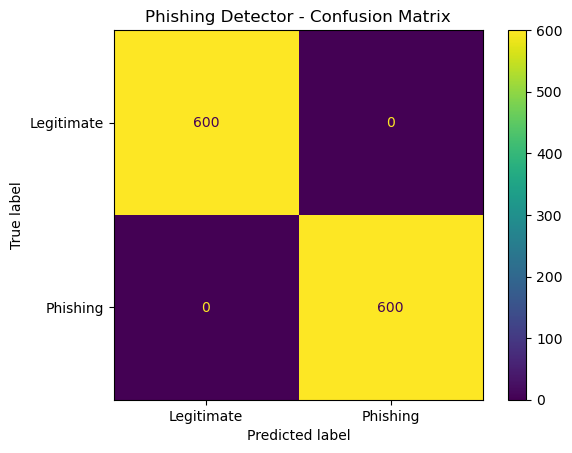

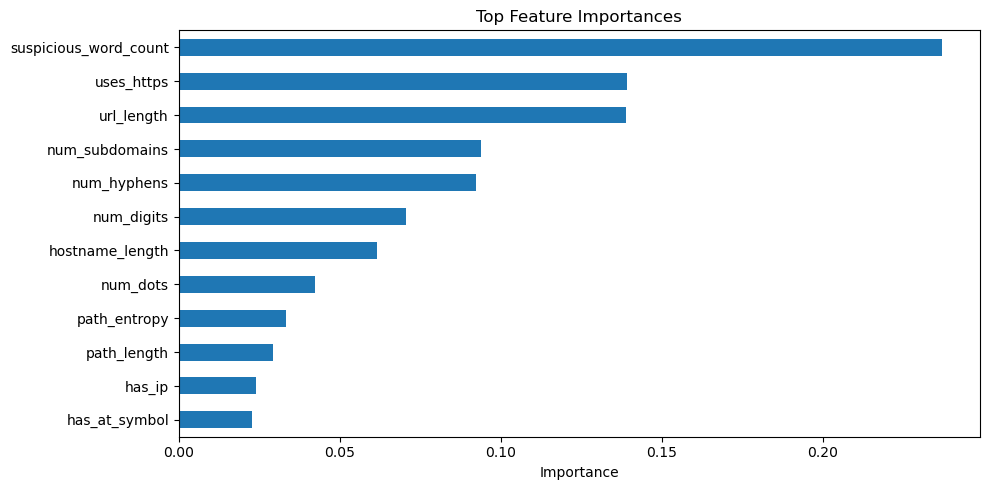

,importance
suspicious_word_count,0.236888
uses_https,0.139020
url_length,0.138988
num_subdomains,0.093867
num_hyphens,0.092292
num_digits,0.070549
hostname_length,0.061495
num_dots,0.042452
path_entropy,0.033296
path_length,0.029392


In [5]:
cm = confusion_matrix(y_test, predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Legitimate', 'Phishing'])
disp.plot()
plt.title('Phishing Detector - Confusion Matrix')
plt.show()

importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(12)
plt.figure(figsize=(10, 5))
importance.sort_values().plot(kind='barh')
plt.title('Top Feature Importances')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

display(importance.to_frame('importance'))

## 5. Predict a new URL

Change `url_to_check` below and run the cell. The model returns a class, probability, and a simple human-readable explanation based on the extracted risk signals.

In [6]:
def explain_url(url, features):
    reasons = []
    if features['has_ip']:
        reasons.append('Uses an IP address instead of a normal domain')
    if features['has_at_symbol']:
        reasons.append('Contains an @ symbol, which can obscure the real destination')
    if features['url_length'] > 100:
        reasons.append('Unusually long URL')
    if features['num_subdomains'] >= 3:
        reasons.append('Large number of subdomains')
    if features['suspicious_word_count'] >= 2:
        reasons.append('Contains multiple security/account-related keywords')
    if features['num_hyphens'] >= 3:
        reasons.append('Contains many hyphens')
    if features['is_shortener']:
        reasons.append('Uses a URL-shortening service')
    if not features['uses_https']:
        reasons.append('Does not use HTTPS')
    if features['num_special_chars'] >= 5:
        reasons.append('Contains many special characters')
    return reasons

def predict_url(url):
    features = extract_features(url)
    vector = pd.DataFrame([features])[feature_cols]
    probability = model.predict_proba(vector)[0]
    phishing_probability = float(probability[1])
    label = 'PHISHING ⚠️' if phishing_probability >= 0.5 else 'LEGITIMATE ✅'

    print('=' * 65)
    print(f'URL: {url}')
    print(f'Prediction: {label}')
    print(f'Phishing probability: {phishing_probability:.2%}')
    print(f'Legitimate probability: {probability[0]:.2%}')
    print('\nRisk indicators:')
    reasons = explain_url(url, features)
    if reasons:
        for reason in reasons:
            print(' •', reason)
    else:
        print(' • No major URL-level risk indicators detected')
    print('=' * 65)
    return features, phishing_probability

url_to_check = 'https://github.com/openai'
predict_url(url_to_check)

URL: https://github.com/openai
Prediction: LEGITIMATE ✅
Phishing probability: 22.40%
Legitimate probability: 77.60%

Risk indicators:
 • No major URL-level risk indicators detected


({'url_length': 25,
  'hostname_length': 10,
  'path_length': 7,
  'num_dots': 1,
  'num_hyphens': 0,
  'num_digits': 0,
  'num_special_chars': 0,
  'num_subdomains': 0,
  'has_ip': 0,
  'uses_https': 1,
  'has_at_symbol': 0,
  'has_question_mark': 0,
  'has_equals': 0,
  'has_percent_encoding': 0,
  'has_port': 0,
  'suspicious_word_count': 0,
  'is_shortener': 0,
  'path_entropy': 3.0},
 0.224)

## 6. Try several examples

In [7]:
examples = [
    'https://www.google.com/search?q=machine+learning',
    'https://github.com/openai',
    'http://paypal-secure-login.xyz/verify/account',
    'http://192.168.44.21/login/verify',
    'https://amazon.com/account/orders',
    'http://microsoft.secure-login.top/account/update?session=928374'
]

results = []
for url in examples:
    features = extract_features(url)
    probability = model.predict_proba(pd.DataFrame([features])[feature_cols])[0, 1]
    results.append({
        'URL': url,
        'Prediction': 'Phishing' if probability >= 0.5 else 'Legitimate',
        'Phishing Probability': f'{probability:.2%}'
    })

display(pd.DataFrame(results))

,URL,Prediction,Phishing Probability
0,https://www.google.com/search?q=machine+learning,Legitimate,0.00%
1,https://github.com/openai,Legitimate,22.40%
2,http://paypal-secure-login.xyz/verify/account,Phishing,97.09%
3,http://192.168.44.21/login/verify,Phishing,90.02%
4,https://amazon.com/account/orders,Legitimate,25.21%
5,http://microsoft.secure-login.top/account/upda...,Phishing,99.99%


## 7. Interactive checker

Run this cell and enter any URL when prompted. The model stays in memory, so no external model file is required.

In [8]:
while True:
    user_url = input("Enter a URL (or type 'quit' to stop): ").strip()
    if user_url.lower() in {'quit', 'exit', 'q'}:
        print('Detector stopped.')
        break
    if not user_url:
        print('Please enter a URL.')
        continue
    predict_url(user_url)

Enter a URL (or type 'quit' to stop):  https://kennykrichardson.onrender.com/


URL: https://kennykrichardson.onrender.com/
Prediction: LEGITIMATE ✅
Phishing probability: 6.80%
Legitimate probability: 93.20%

Risk indicators:
 • No major URL-level risk indicators detected


Enter a URL (or type 'quit' to stop):  quit


Detector stopped.


### Conclusion

This project demonstrates a complete ML workflow: **feature engineering → dataset generation → train/test split → Random Forest training → evaluation → prediction → explainable output**.

For a production security system, the next step would be training on a large, independently collected dataset of real benign and malicious URLs and continuously validating the model against new phishing campaigns.